# Notebook 2: Parameter Estimation from Concentration Data

This notebook demonstrates parameter estimation using concentration measurement data
from kipet's Example 12 dataset.

**Data:** `../../../kipet/examples/example_12/data/Ex_1_C_data.txt`  
Format: 3-column space-separated (time, component, value)

**Reaction system:** A → B → C  
**Goal:** Recover rate constants k1 and k2 from noisy concentration measurements

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kipetax

## Load the concentration data

The data file has three columns: time, component name, concentration value.
We convert it to a DataFrame with time as the index and components as columns.

In [2]:
DATA_FILE = '../../kipet/examples/example_12/data/Ex_1_C_data.txt'

# Load the 3-column format and pivot to time × component matrix
raw = pd.read_csv(DATA_FILE, sep=r'\s+', header=None, names=['time', 'component', 'value'])
C_data = raw.pivot(index='time', columns='component', values='value')
C_data.index.name = None
C_data.columns.name = None

print(f"Data shape: {C_data.shape}  (times × components)")
print(f"Time range: {C_data.index[0]:.3f} to {C_data.index[-1]:.3f}")
print(f"Components: {list(C_data.columns)}")
C_data.head()

Data shape: (300, 3)  (times × components)
Time range: 0.000 to 9.969
Components: ['A', 'B', 'C']


,A,B,C
0.0000,0.001027,0.000000,0.000013
0.0333,0.001015,0.000002,0.000021
0.0667,0.001007,0.000013,0.000018
0.1000,0.000993,0.000025,0.000014
0.1334,0.000982,0.000035,0.000012


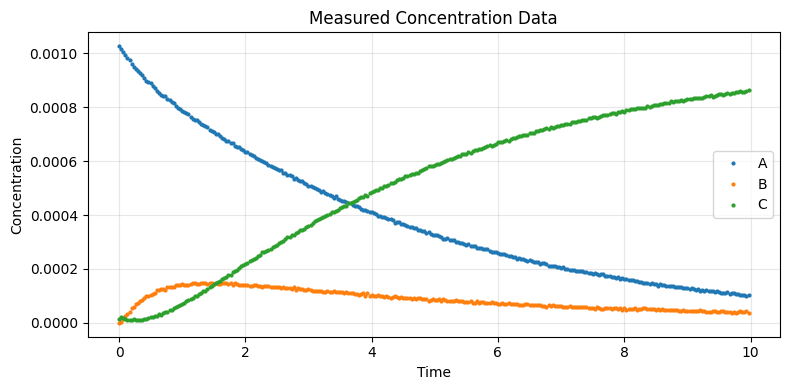

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for comp in C_data.columns:
    ax.plot(C_data.index, C_data[comp], '.', label=comp, markersize=4)
ax.set_xlabel('Time')
ax.set_ylabel('Concentration')
ax.set_title('Measured Concentration Data')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Build the reaction model

We use initial guesses for k1 and k2 and let the optimizer find the true values.

In [4]:
r1 = kipetax.ReactionModel('conc-pe')

# Parameters with initial guesses and bounds
k1 = r1.parameter('k1', value=0.5, bounds=(0.01, 10.0))
k2 = r1.parameter('k2', value=0.1, bounds=(0.01, 5.0))

# Components with initial conditions from the data
A = r1.component('A', value=float(C_data['A'].iloc[0]))
B = r1.component('B', value=float(C_data['B'].iloc[0]))
C = r1.component('C', value=float(C_data['C'].iloc[0]))

# ODEs: A → B → C
r1.add_ode('A', -k1 * A)
r1.add_ode('B',  k1 * A - k2 * B)
r1.add_ode('C',  k2 * B)

# Add the concentration data
r1.add_data(name='conc_data', data=C_data)

# Set discretization (finer than the data sampling)
r1.set_discretization(nfe=60, ncp=3)

print("Model built successfully")
print(f"Time span: 0 to {C_data.index[-1]:.2f}")

Model built successfully
Time span: 0 to 9.97


## Run parameter estimation

We provide known (or estimated) variances for each component measurement.

In [5]:
# Provide measurement variances (noise level squared)
# These can be estimated from replicate measurements or from the variance estimator
variances = {'A': 1e-6, 'B': 1e-6, 'C': 1e-6}

r1.run_opt(variances=variances)
ro = r1.results_dict['p_estimator']
print(f"Optimization status: {ro.status}")

E0712 13:12:40.942889 1774234 slow_operation_alarm.cc:73] 
********************************
[Compiling module jit_fn for CPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


E0712 13:13:25.318403 1773872 slow_operation_alarm.cc:140] The operation took 2m44.392314s

********************************
[Compiling module jit_fn for CPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


Parameter estimation complete: status=optimal
  k1                   = 0.221542
  k2                   = 0.924153
Optimization status: optimal


## Results

In [6]:
print("Estimated parameters:")
for name, val in ro.P.items():
    print(f"  {name} = {val:.6f}")

print(f"\nObjective value: {ro.objective:.4e}")

Estimated parameters:
  k1 = 0.221542
  k2 = 0.924153

Objective value: 2.4639e-01


## Compare fitted trajectories to measurements

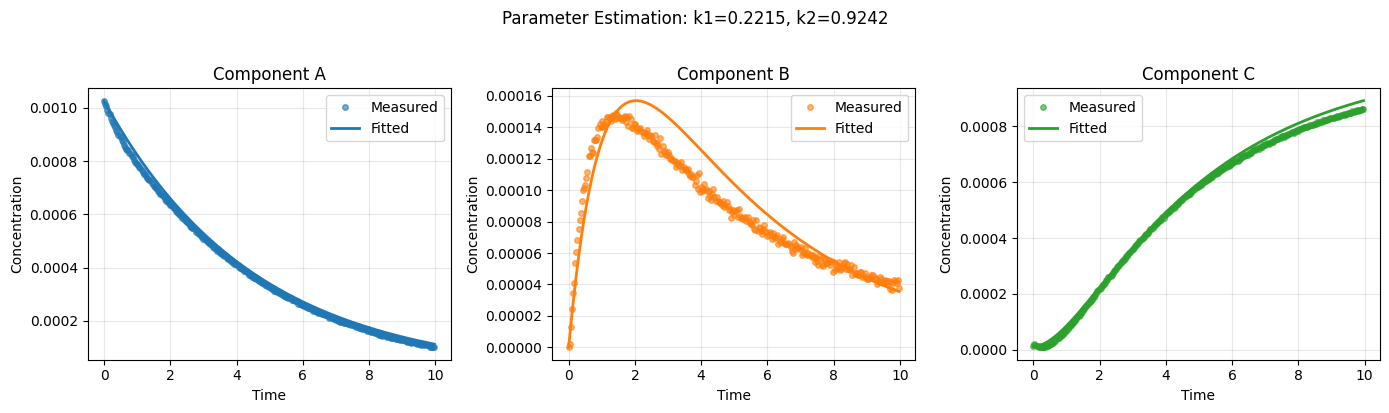

In [7]:
Z = ro.Z  # Fitted concentration profiles

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = {'A': 'tab:blue', 'B': 'tab:orange', 'C': 'tab:green'}

for ax, comp in zip(axes, ['A', 'B', 'C']):
    color = colors[comp]
    # Measurements
    ax.plot(C_data.index, C_data[comp], 'o', color=color, markersize=4,
            alpha=0.6, label='Measured')
    # Fitted profile
    ax.plot(Z.index, Z[comp], '-', color=color, linewidth=2, label='Fitted')
    ax.set_xlabel('Time')
    ax.set_ylabel('Concentration')
    ax.set_title(f'Component {comp}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle(
    f'Parameter Estimation: k1={ro.P["k1"]:.4f}, k2={ro.P["k2"]:.4f}',
    y=1.02
)
plt.tight_layout()
plt.show()

## Residuals analysis

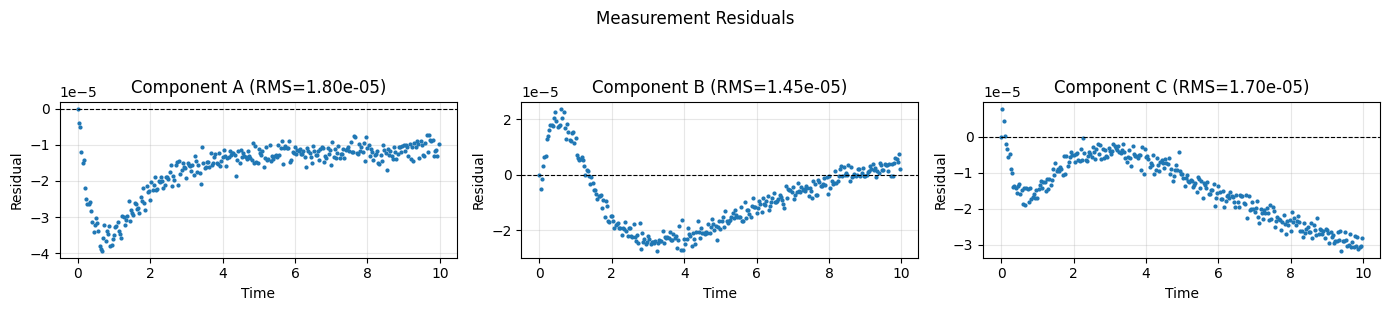

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))

for ax, comp in zip(axes, ['A', 'B', 'C']):
    # Interpolate fitted profile to measurement times
    fitted_at_meas = np.interp(C_data.index, Z.index, Z[comp])
    residuals = C_data[comp].values - fitted_at_meas
    ax.plot(C_data.index, residuals, '.', markersize=4)
    ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
    ax.set_xlabel('Time')
    ax.set_ylabel('Residual')
    ax.set_title(f'Component {comp} (RMS={np.sqrt(np.mean(residuals**2)):.2e})')
    ax.grid(True, alpha=0.3)

plt.suptitle('Measurement Residuals', y=1.02)
plt.tight_layout()
plt.show()